Device: cpu
FOUND: C:\Users\lenovo\Desktop\Sathyaraj\sathya\data\output\X.npy
FOUND: C:\Users\lenovo\Desktop\Sathyaraj\sathya\data\output\y.npy
FOUND: C:\Users\lenovo\Desktop\Sathyaraj\sathya\data\output\groups.npy
FOUND: C:\Users\lenovo\Desktop\Sathyaraj\sathya\src\models\bearing_cnn.pth

Dataset loaded successfully
X shape: (5926, 1, 1024)
y shape: (5926,)
Unique recordings: 40

Unique recordings per class:
Normal: 4
Inner-race fault: 12
Outer-race fault: 12
Ball fault: 12

Test dataset
Test windows: 1184
Test recordings: 7
Test class counts:
Normal: 474
Inner-race fault: 236
Outer-race fault: 237
Ball fault: 237

Trained model loaded successfully!
Model path: C:\Users\lenovo\Desktop\Sathyaraj\sathya\src\models\bearing_cnn.pth
Best validation loss: 0.0010226038797327358
Saved window size: 1024

BEARING FAULT DETECTION: TEST RESULTS
Test accuracy: 89.27%
Correct predictions: 1057
Incorrect predictions: 127
Total test windows: 1184

Classification report:

                  precision  

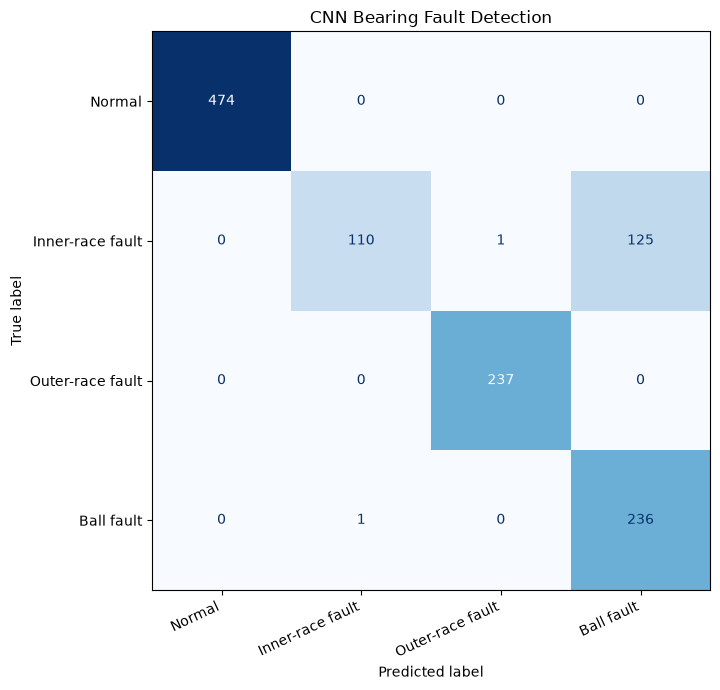


First 20 predictions:


,recording,actual_id,predicted_id,confidence,actual_class,predicted_class,correct
0,B007_1.mat,3,3,1.000000,Ball fault,Ball fault,True
1,B007_1.mat,3,3,0.999999,Ball fault,Ball fault,True
2,B007_1.mat,3,3,1.000000,Ball fault,Ball fault,True
3,B007_1.mat,3,3,1.000000,Ball fault,Ball fault,True
4,B007_1.mat,3,3,1.000000,Ball fault,Ball fault,True
5,B007_1.mat,3,3,0.999999,Ball fault,Ball fault,True
6,B007_1.mat,3,3,0.999998,Ball fault,Ball fault,True
7,B007_1.mat,3,3,1.000000,Ball fault,Ball fault,True
8,B007_1.mat,3,3,1.000000,Ball fault,Ball fault,True
9,B007_1.mat,3,3,1.000000,Ball fault,Ball fault,True



Incorrect predictions:


,recording,actual_id,predicted_id,confidence,actual_class,predicted_class,correct
176,B014_2.mat,3,1,0.613425,Ball fault,Inner-race fault,False
238,IR014_2.mat,1,3,0.989895,Inner-race fault,Ball fault,False
251,IR014_2.mat,1,3,0.855733,Inner-race fault,Ball fault,False
253,IR014_2.mat,1,3,0.722552,Inner-race fault,Ball fault,False
256,IR014_2.mat,1,3,0.886955,Inner-race fault,Ball fault,False
267,IR014_2.mat,1,2,0.661333,Inner-race fault,Outer-race fault,False
270,IR014_2.mat,1,3,0.843734,Inner-race fault,Ball fault,False
278,IR014_2.mat,1,3,0.832687,Inner-race fault,Ball fault,False
295,IR014_2.mat,1,3,0.700431,Inner-race fault,Ball fault,False
299,IR014_2.mat,1,3,0.611921,Inner-race fault,Ball fault,False



Most common classification errors:


,actual_class,predicted_class,count
1,Inner-race fault,Ball fault,125
0,Ball fault,Inner-race fault,1
2,Inner-race fault,Outer-race fault,1



Accuracy by recording:


,recording,actual_class,windows,correct,accuracy
0,B007_1.mat,Ball fault,118,118,100.00
1,B014_2.mat,Ball fault,119,118,99.16
2,IR014_2.mat,Inner-race fault,118,100,84.75
3,IR014_3.mat,Inner-race fault,118,10,8.47
4,Normal_3.mat,Normal,474,474,100.00
5,OR0076_0.mat,Outer-race fault,119,119,100.00
6,OR0146_3.mat,Outer-race fault,118,118,100.00



Testing notebook completed.


In [1]:

# ============================================================
# CNN-BASED BEARING FAULT DETECTION
# Complete Testing Notebook
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ============================================================
# 1. CONFIGURATION AND PATHS
# ============================================================

PROJECT_DIR = Path(r"C:\Users\lenovo\Desktop\Sathyaraj\sathya")

X_PATH = PROJECT_DIR / "data" / "output" / "X.npy"
Y_PATH = PROJECT_DIR / "data" / "output" / "y.npy"
GROUPS_PATH = PROJECT_DIR / "data" / "output" / "groups.npy"

MODEL_PATH = PROJECT_DIR / "src" / "models" / "bearing_cnn.pth"

device = torch.device("cpu")
SEED = 42
BATCH_SIZE = 64

CLASS_NAMES = {
    0: "Normal",
    1: "Inner-race fault",
    2: "Outer-race fault",
    3: "Ball fault"
}

print("Device:", device)

for path in [X_PATH, Y_PATH, GROUPS_PATH, MODEL_PATH]:
    print(f"{'FOUND' if path.exists() else 'MISSING'}: {path}")

if not all(
    path.exists()
    for path in [X_PATH, Y_PATH, GROUPS_PATH, MODEL_PATH]
):
    raise FileNotFoundError(
        "One or more required files could not be found. "
        "Verify the paths above."
    )

# ============================================================
# 2. LOAD PREPROCESSED DATA
# ============================================================

X = np.load(X_PATH).astype(np.float32)
y = np.load(Y_PATH).astype(np.int64)
groups = np.load(GROUPS_PATH).astype(str)

assert len(X) == len(y) == len(groups)
assert X.ndim == 3 and X.shape[1] == 1

print("\nDataset loaded successfully")
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Unique recordings:", len(np.unique(groups)))

# ============================================================
# 3. RECREATE THE RECORDING-LEVEL TEST SPLIT
# ============================================================
# This reproduces the class-wise split procedure used during
# training, assuming the same data order and random seed.

rng = np.random.default_rng(SEED)
unique_groups = np.unique(groups)

group_to_label = {}

for group in unique_groups:
    labels = np.unique(y[groups == group])

    if len(labels) != 1:
        raise ValueError(
            f"Recording {group} has multiple class labels: {labels}"
        )

    group_to_label[group] = int(labels[0])

test_groups = []

print("\nUnique recordings per class:")

for class_id, class_name in CLASS_NAMES.items():

    class_groups = np.array([
        group for group in unique_groups
        if group_to_label[group] == class_id
    ])

    rng.shuffle(class_groups)
    n = len(class_groups)

    print(f"{class_name}: {n}")

    if n < 3:
        raise ValueError(
            f"{class_name} has fewer than three recordings."
        )

    n_test = max(1, round(n * 0.15))
    n_val = max(1, round(n * 0.15))

    while n_test + n_val >= n:
        if n_val > 1:
            n_val -= 1
        elif n_test > 1:
            n_test -= 1
        else:
            raise ValueError(
                f"Cannot split class {class_name}."
            )

    test_groups.extend(class_groups[:n_test])

test_groups = np.array(test_groups)

test_idx = np.flatnonzero(
    np.isin(groups, test_groups)
)

X_test = X[test_idx]
y_test = y[test_idx]
groups_test = groups[test_idx]

print("\nTest dataset")
print("Test windows:", len(X_test))
print("Test recordings:", len(np.unique(groups_test)))

print("Test class counts:")
for class_id, class_name in CLASS_NAMES.items():
    print(
        f"{class_name}:",
        int(np.sum(y_test == class_id))
    )

# ============================================================
# 4. DEFINE THE CNN ARCHITECTURE
# ============================================================

class BearingCNN(nn.Module):
    def __init__(self, num_classes=4):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv1d(1, 16, kernel_size=7, padding=3),
            nn.ReLU(),
            nn.MaxPool1d(2),

            nn.Conv1d(16, 32, kernel_size=5, padding=2),
            nn.ReLU(),
            nn.MaxPool1d(2),

            nn.Conv1d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.AdaptiveAvgPool1d(1)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(32, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

# ============================================================
# 5. LOAD THE TRAINED MODEL CHECKPOINT
# ============================================================

checkpoint = torch.load(
    MODEL_PATH,
    map_location=device,
    weights_only=True
)

model = BearingCNN(num_classes=4).to(device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("\nTrained model loaded successfully!")
print("Model path:", MODEL_PATH)
print(
    "Best validation loss:",
    checkpoint.get("best_validation_loss", "Not recorded")
)
print(
    "Saved window size:",
    checkpoint.get("window_size", "Not recorded")
)

# ============================================================
# 6. CREATE THE TEST DATA LOADER
# ============================================================

test_dataset = TensorDataset(
    torch.from_numpy(X_test),
    torch.from_numpy(y_test)
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# ============================================================
# 7. RUN INFERENCE
# ============================================================

all_predictions = []
all_probabilities = []

model.eval()

with torch.no_grad():
    for inputs, targets in test_loader:

        inputs = inputs.to(device)

        logits = model(inputs)
        probabilities = torch.softmax(logits, dim=1)
        predictions = logits.argmax(dim=1)

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_probabilities.extend(
            probabilities.cpu().numpy()
        )

y_pred = np.array(all_predictions)
y_prob = np.array(all_probabilities)

# ============================================================
# 8. OVERALL TEST RESULTS
# ============================================================

test_accuracy = accuracy_score(y_test, y_pred)

print("\n" + "=" * 55)
print("BEARING FAULT DETECTION: TEST RESULTS")
print("=" * 55)

print(f"Test accuracy: {test_accuracy:.2%}")
print(f"Correct predictions: {np.sum(y_test == y_pred)}")
print(f"Incorrect predictions: {np.sum(y_test != y_pred)}")
print(f"Total test windows: {len(y_test)}")

# ============================================================
# 9. CLASSIFICATION REPORT
# ============================================================

print("\nClassification report:\n")

print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1, 2, 3],
        target_names=[
            CLASS_NAMES[i] for i in range(4)
        ],
        zero_division=0
    )
)

# ============================================================
# 10. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1, 2, 3]
)

print("Confusion matrix:")
print(cm)

fig, ax = plt.subplots(figsize=(9, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        CLASS_NAMES[i] for i in range(4)
    ]
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("CNN Bearing Fault Detection")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

# ============================================================
# 11. DETAILED PREDICTIONS
# ============================================================

results = pd.DataFrame({
    "recording": groups_test,
    "actual_id": y_test,
    "predicted_id": y_pred,
    "confidence": np.max(y_prob, axis=1)
})

results["actual_class"] = results["actual_id"].map(CLASS_NAMES)
results["predicted_class"] = results["predicted_id"].map(CLASS_NAMES)
results["correct"] = results["actual_id"] == results["predicted_id"]

print("\nFirst 20 predictions:")
display(results.head(20))

print("\nIncorrect predictions:")

errors = results[~results["correct"]]

if errors.empty:
    print("No incorrect predictions.")
else:
    display(errors.head(50))

    print("\nMost common classification errors:")
    display(
        errors.groupby(
            ["actual_class", "predicted_class"]
        ).size()
        .reset_index(name="count")
        .sort_values("count", ascending=False)
    )

# ============================================================
# 12. ACCURACY BY ORIGINAL RECORDING
# ============================================================

print("\nAccuracy by recording:")

recording_report = (
    results.groupby(["recording", "actual_class"])
    .agg(
        windows=("correct", "size"),
        correct=("correct", "sum"),
        accuracy=("correct", "mean")
    )
    .reset_index()
)

recording_report["accuracy"] *= 100

display(recording_report.round(2))

print("\nTesting notebook completed.")
